# Well performance workflow: virtual flow metering and build-up analysis

SOCAR Hackathon 2026, *Intelligent Well Performance Analysis*.

1. **Data quality**: clean the per-minute sensor data and repair the well tests.
2. **Phase 1, VFM**: predict daily oil, water and gas for every well from the downhole pressure, calibrated on the periodic well tests.
3. **Phase 2, PTA**: find every shut-in and interpret the pressure build-up (Horner slope m, permeability k, skin, Δp skin), using the VFM oil rate.
4. **Export**: result files (CSV + Excel), reports, PTA plots and the trained model (`models/vfm_model.pkl`).
5. **Using the saved model on new data**: the path the application uses.

All code lives in the `wellperf` package (`src/wellperf`); this notebook runs it end to end. The tables show aggregated
results, not raw data rows.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from wellperf import config as C, pipeline as PL, vfm as V, static_plots as SP
from wellperf.candidates import backtest_candidates, score_candidates
from wellperf.interpret import interpret_text

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 3)
%matplotlib inline

## 1. Train on the training data and run the full workflow

In [2]:
import time
t = time.time()
ws = PL.train()
print(f"Workflow finished in {time.time() - t:.0f} s")
print(f"Wells: {ws.vfm_daily.well_name.nunique()} · well tests used for calibration: {len(ws.tests_feat)} · "
      f"well-days predicted: {len(ws.vfm_daily):,} · shut-ins interpreted: {len(ws.pta)}")

Workflow finished in 33 s
Wells: 10 · well tests used for calibration: 85 · well-days predicted: 2,730 · shut-ins interpreted: 6


### Data quality

Per-minute data are put on a regular 1-minute grid per well. Duplicates are averaged; the −999.25 missing-value code and
physically impossible values are removed; spikes are caught by a Hampel filter; frozen sensors are removed; gaps up to
10 minutes are interpolated. Minutes affected, per issue and well:

In [3]:
rep = ws.hf_qc.set_index("well_name")
issue = rep[[c for c in rep.columns if "|" in c]].T
issue.index = pd.MultiIndex.from_tuples([tuple(i.split("|")) for i in issue.index], names=["signal", "issue"])
issue.groupby(level="issue").sum().T

issue,frozen,interpolated,out_of_bounds,sentinel,spikes,still_missing
well_name,,,,,,
GL-01,0,747,0,566,46,2145
GL-02,0,838,2,881,45,5880
GL-03,0,848,0,1191,42,14785
GL-04,0,691,0,679,37,14605
GL-05,0,772,0,800,57,10465
GL-06,0,938,0,720,33,15595
GL-07,0,716,0,789,37,2000
GL-08,0,675,0,541,59,2085
GL-09,0,703,0,610,58,10765


Well tests carry redundant columns (oil, water, liquid, water cut, GOR, gas), so errors show up as inconsistencies. Corrections applied:

In [4]:
ws.test_issues.groupby(["issue", "column"]).size().rename("tests corrected").reset_index()

,issue,column,tests corrected
0,negative value (sign flip) -> abs,gas_lift_rate_mscfd,2
1,negative value (sign flip) -> abs,gas_rate_mscfd,1
2,negative value (sign flip) -> abs,total_gas_rate_mscfd,1
3,negative value (sign flip) -> abs,water_rate_stbd,1
4,reported in sm3/d -> converted to Mscf/d,gas_rate_mscfd,9
5,reported in sm3/d -> converted to Mscf/d,total_gas_rate_mscfd,9


## 2. Phase 1: virtual flow metering

The wells produce undersaturated oil (flowing bottom-hole pressure 2,300–3,700 psia, bubble point about 1,200–1,600 psia), so
per well:

* liquid rate $q_L = J\,(\bar p_r(t) - p_{wf})$ with reservoir pressure $\bar p_r$ drifting linearly in time, $J$ ridge-regularised toward a pooled value;
* water cut follows a linear trend; GOR is the test mean shrunk toward the solution GOR $R_s(p_b)$;
* oil = $q_L(1-WC)$, water = $q_L\,WC$, gas = oil × GOR (lift gas excluded); daily volume = rate × hours on stream.

**Validation.** Forward-chaining: every test is predicted from earlier tests only (as in deployment). Leave-one-test-out:
interpolation between tests. Baseline: carry the last well test forward.

In [5]:
print("Forward-chaining"); display(V.score(ws.backtest_forward).round(2))
print("Leave-one-test-out"); display(V.score(ws.backtest_loto).round(2))

Forward-chaining


,model,n_tests,oil MAE,oil MAPE %,oil bias %,water MAE,water MAPE %,water bias %,gas MAE,gas MAPE %,gas bias %
0,VFM,55,41.74,3.5,-0.29,31.54,4.82,-0.82,16.47,5.85,1.12
1,Last test carried forward,55,70.38,6.0,3.10,37.67,5.85,-0.98,24.73,9.23,3.68


Leave-one-test-out


,model,n_tests,oil MAE,oil MAPE %,oil bias %,water MAE,water MAPE %,water bias %,gas MAE,gas MAPE %,gas bias %
0,VFM,85,29.80,2.51,0.21,22.86,3.62,0.26,15.94,5.64,1.15
1,Last test carried forward,75,66.45,5.64,3.13,36.87,5.61,-0.84,25.12,9.15,4.03


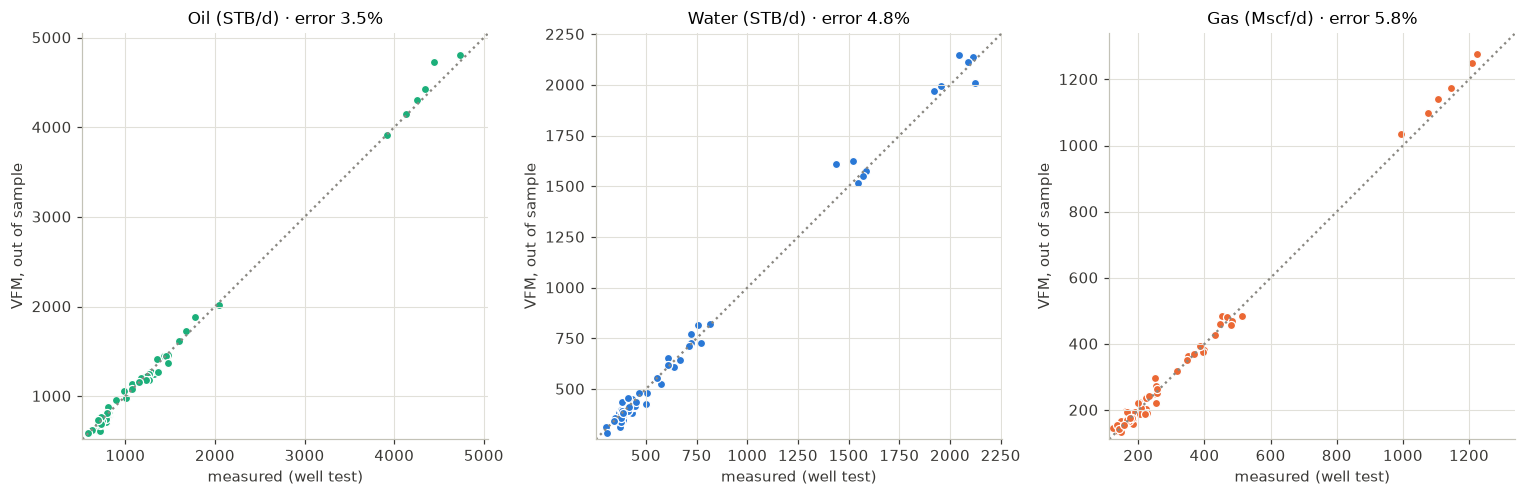

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, (ph, label, col) in zip(axes, SP.PHASES):
    bt = ws.backtest_forward.dropna(subset=[ph + "_vfm"])
    lo, hi = bt[[ph, ph + "_vfm"]].min().min() * 0.9, bt[[ph, ph + "_vfm"]].max().max() * 1.05
    ax.plot([lo, hi], [lo, hi], ":", color=SP.MUTED)
    ax.scatter(bt[ph], bt[ph + "_vfm"], s=28, color=col, edgecolor="white", linewidth=0.8)
    mape = (abs(bt[ph + "_vfm"] - bt[ph]) / bt[ph]).mean() * 100
    ax.set(xlim=(lo, hi), ylim=(lo, hi), xlabel="measured (well test)", ylabel="VFM, out of sample",
           title=f"{label} · error {mape:.1f}%")
    ax.set_aspect("equal")
plt.tight_layout(); plt.show()

### Why this model and not another

Every candidate is scored with the same forward-chaining backtest on the same tests. *Per-well time trend* ignores the
sensors; *choke-flow ridge* is a Gilbert-type model (choke size, wellhead pressure, downhole minus wellhead pressure,
gas-lift rate, temperature) pooled across wells with a per-well offset; *gradient-boosted trees* learn from every sensor
feature plus well identity and time. With under ten tests per well, the model that already knows the shape of inflow needs
the least data, and it extrapolates the reservoir-pressure decline instead of flattening as trees do.

In [7]:
cands = ws.candidates if ws.candidates is not None else score_candidates(backtest_candidates(ws.tests_feat, ws.static))
cands.round(2)

,model,n_tests,oil MAPE %,water MAPE %,gas MAPE %
0,Physics IPR model (VFM),55,3.50,4.82,5.85
1,Last test carried forward,55,6.00,5.85,9.23
2,Per-well time trend,55,6.00,6.51,7.06
3,Gradient-boosted trees,55,6.77,12.92,13.70
4,Choke-flow ridge (pooled),55,7.22,5.78,10.58


Prediction ranges (5th and 95th percentile of the out-of-sample relative errors) and per-well parameters:

In [8]:
display(pd.DataFrame(ws.model.rel_err_q).T.rename(columns={"q05": "low", "q95": "high"}))
pd.DataFrame([vars(p) for p in ws.model.params.values()])[
    ["well_name", "n_tests", "J", "J_source", "wc_c", "wc_d", "gor", "rs_pb"]].round(3)

,low,high,n
oil_rate_stbd,-0.060,0.087,55.0
water_rate_stbd,-0.080,0.118,55.0
gas_rate_mscfd,-0.148,0.146,55.0


,well_name,n_tests,J,J_source,wc_c,wc_d,gor,rs_pb
0,GL-01,9,2.195,well regression + prior,40.257,0.028,274.764,277.8
1,GL-02,8,1.866,well regression + prior,50.091,0.029,301.808,301.4
2,GL-03,9,0.500,well regression + prior,31.495,0.015,221.607,222.0
3,GL-04,9,1.179,well regression + prior,29.440,0.015,242.407,237.5
4,GL-05,8,0.768,well regression + prior,31.086,0.028,315.392,325.7
5,GL-06,9,6.128,well regression + prior,37.893,0.022,211.679,217.0
6,GL-07,9,19.195,well regression + prior,25.553,0.036,263.671,268.3
7,GL-08,8,2.445,well regression + prior,16.885,0.030,333.892,336.2
8,GL-09,9,2.350,well regression + prior,17.768,0.031,161.400,160.0
9,GL-10,7,2.467,well regression + prior,21.646,0.025,228.725,230.0


Daily rates for each well (line, with the 90% range shaded) against the measured well tests (circles):

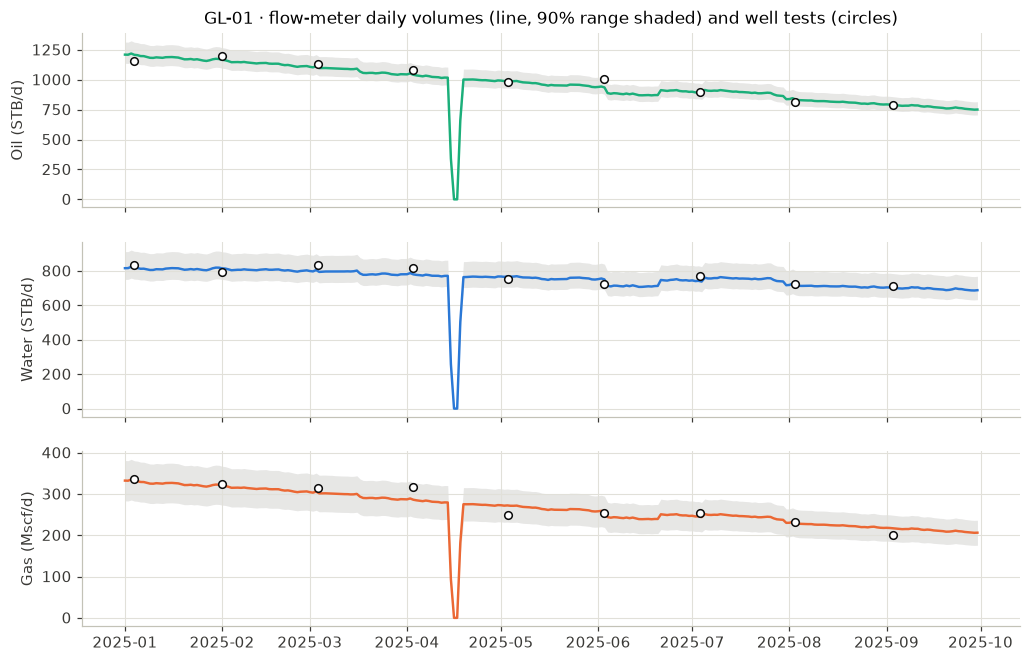

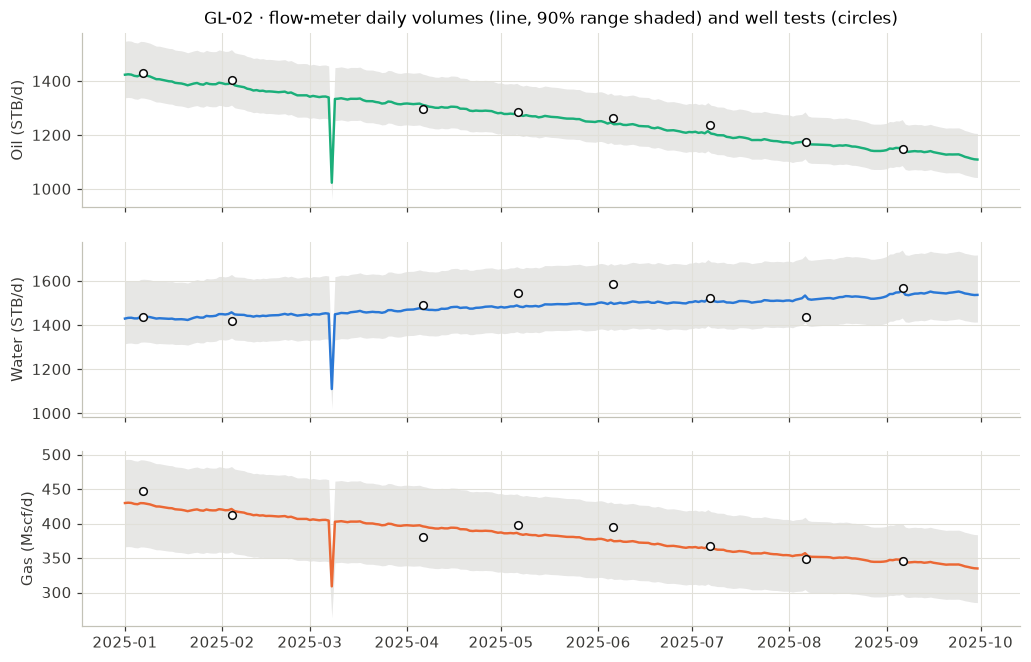

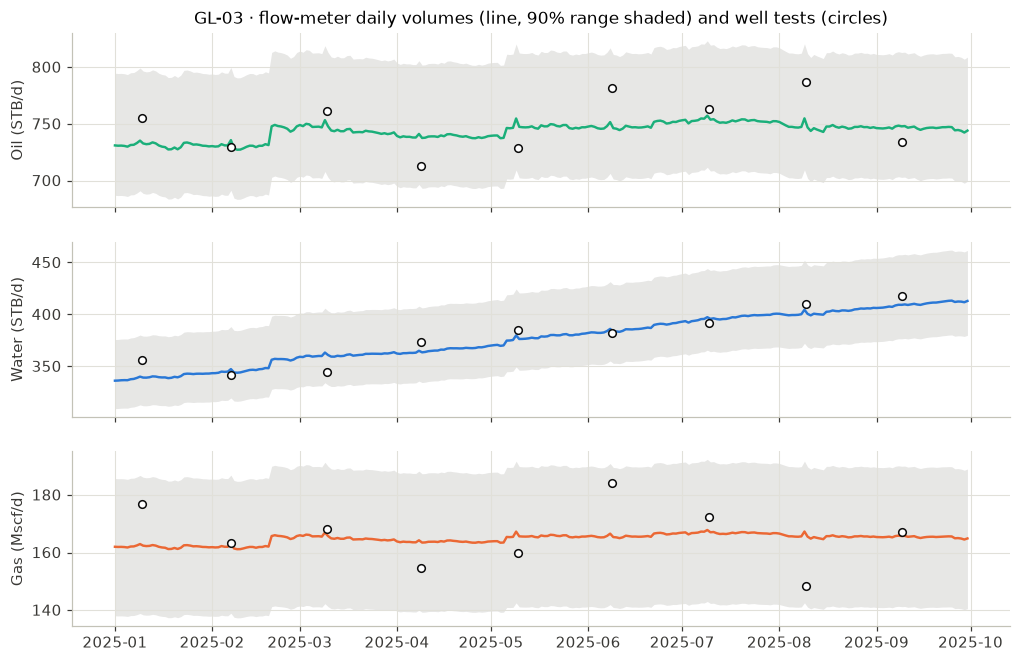

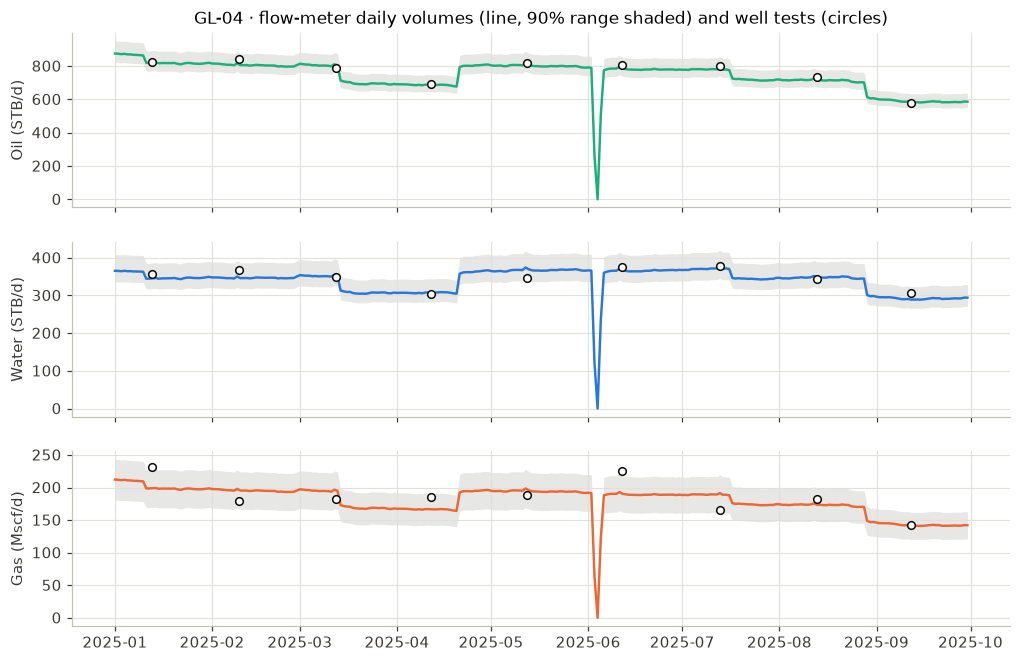

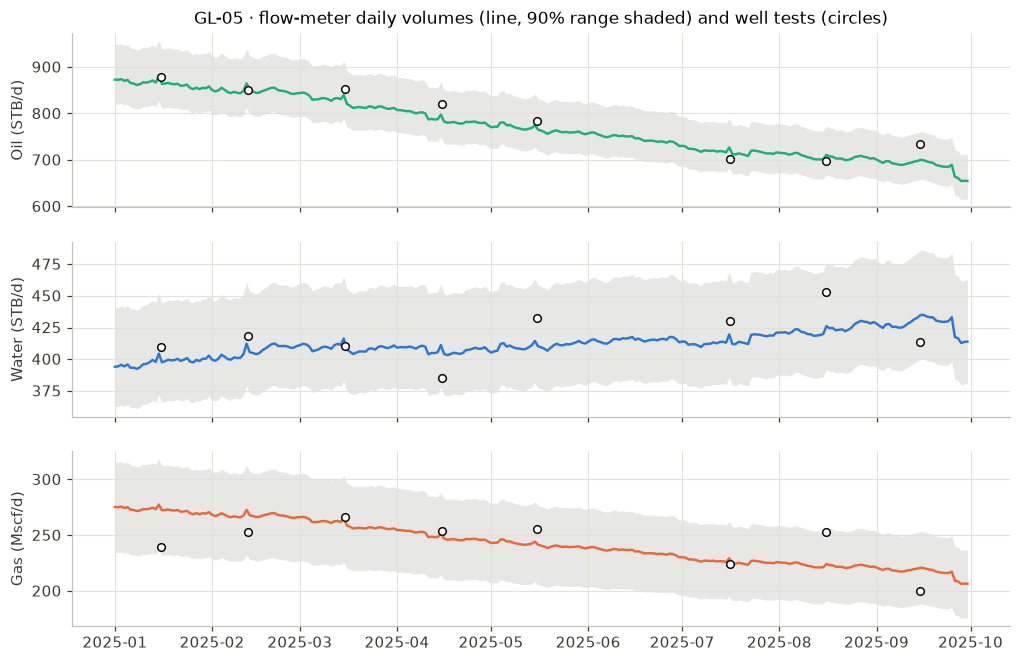

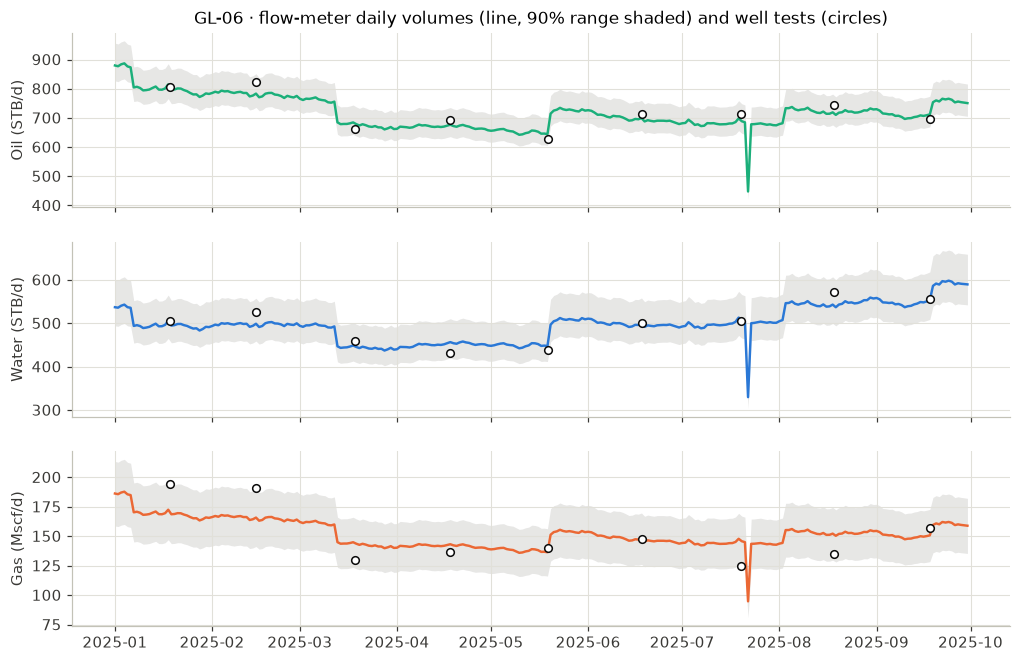

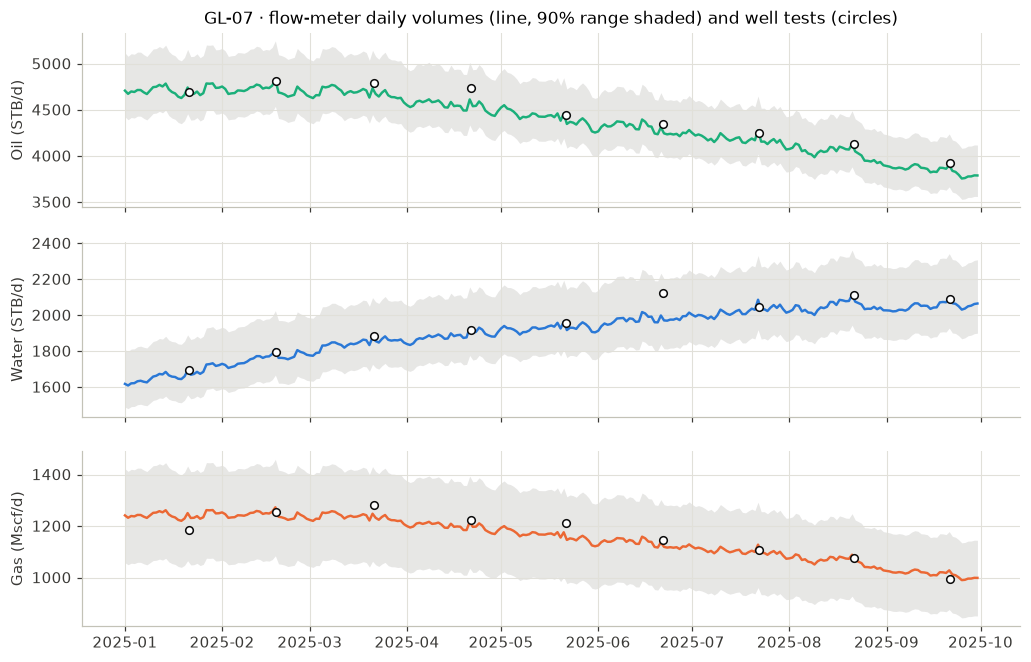

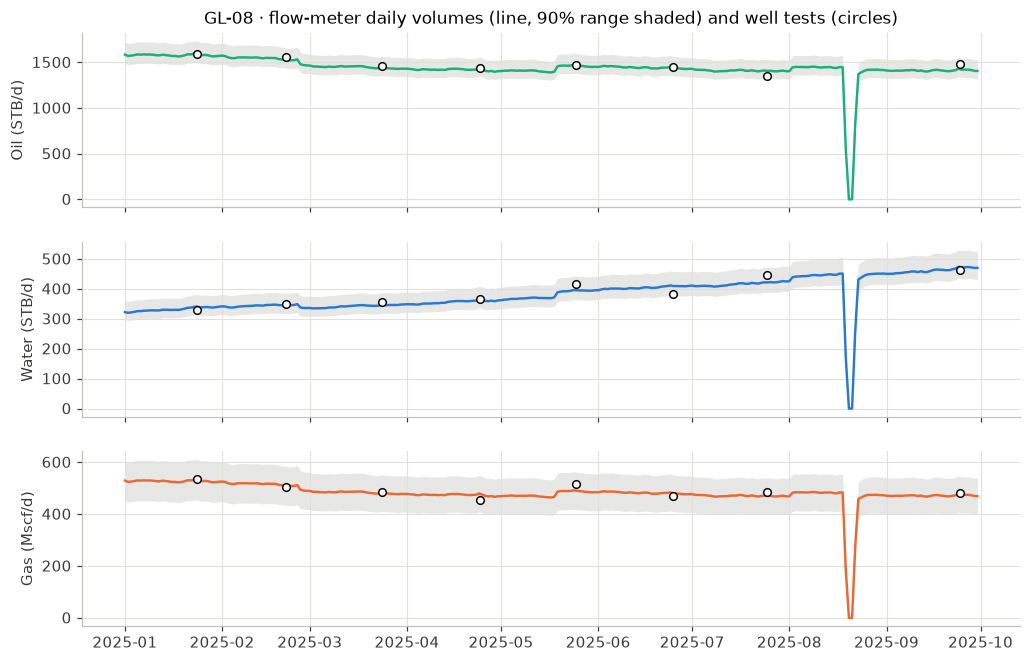

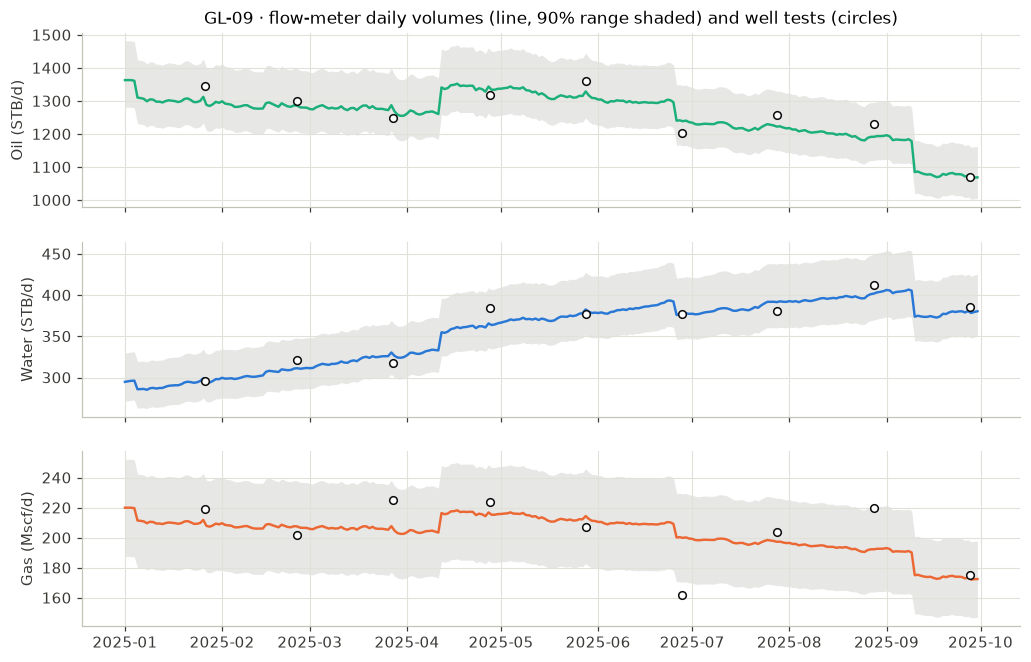

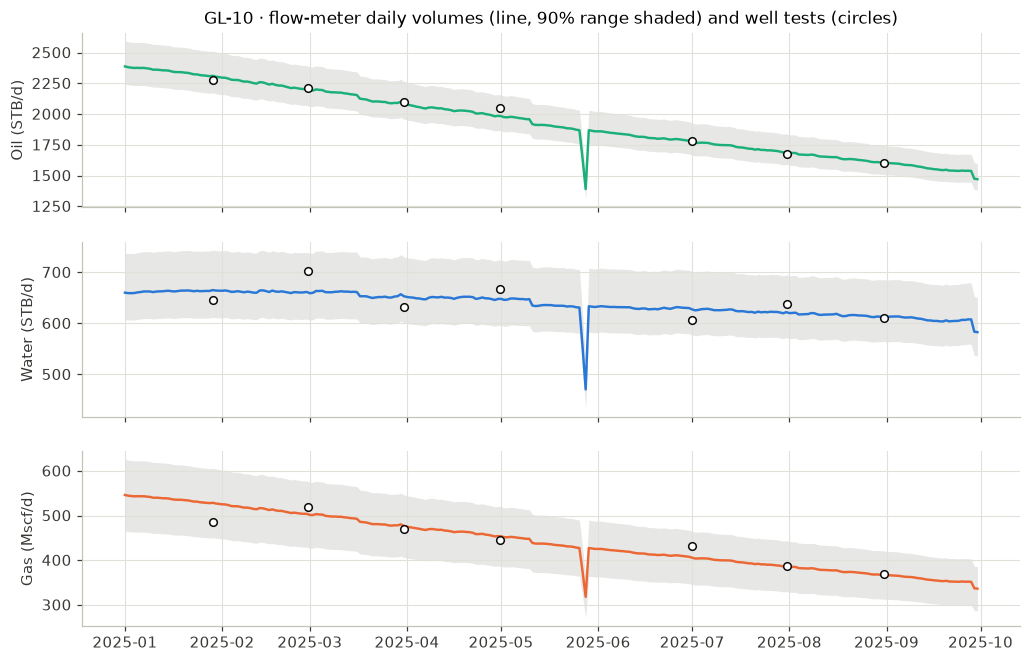

In [9]:
for w in sorted(ws.model.params):
    fig = SP.rate_figure(ws.vfm_daily, ws.tests, w); plt.show()

In [10]:
print("Phase 1 result: average daily volumes per well over the period")
PL.vfm_deliverable(ws.vfm_daily).groupby("well_name")[["oil_rate_stbd", "water_rate_stbd", "gas_rate_mscfd"]].mean().round(1)

Phase 1 result: average daily volumes per well over the period


,oil_rate_stbd,water_rate_stbd,gas_rate_mscfd
well_name,,,
GL-01,960.0,749.1,263.8
GL-02,1263.5,1486.3,381.3
GL-03,743.6,376.7,164.8
GL-04,742.3,339.1,179.9
GL-05,771.8,412.3,243.4
GL-06,718.9,498.4,152.2
GL-07,4379.9,1908.4,1154.9
GL-08,1440.3,381.7,480.9
GL-09,1259.1,355.0,203.2


## 3. Phase 2: build-up analysis

Shut-ins are found where gas-lift injection stops (or the choke closes) for at least an hour. For each build-up:
log-resampled pressure → Bourdet derivative on equivalent time → radial-flow window = flattest derivative stretch after
wellbore storage → Horner fit gives m, p* and p1hr, and from them

$k = 162.6\,qB\mu/(mh)$, $\;s = 1.151[(p_{1hr}-p_{wf})/m - \log(k/(\phi\mu c_t r_w^2)) + 3.23]$, $\;\Delta p_{skin} = 0.87\,m\,s$.

q is the VFM oil rate of the last full day before the shut-in; $t_p = 24 N_p/q$.

In [11]:
PL.pta_deliverable(ws.pta)

,well_name,t_shut,duration_hr,m_psi_cycle,k_md,skin,dP_skin
0,GL-01,2025-04-15 08:00:00,72.02,22.803,110.864,5.977,118.579
1,GL-02,2025-03-08 14:23:00,5.67,53.062,58.640,-0.581,-26.839
2,GL-04,2025-06-03 08:00:00,48.02,146.094,53.821,-1.283,-163.032
3,GL-06,2025-07-22 03:11:00,8.02,15.252,293.858,1.847,24.504
4,GL-08,2025-08-19 09:00:00,72.02,93.273,42.394,-1.643,-133.295
5,GL-10,2025-05-27 21:04:00,9.02,27.793,193.908,2.284,55.231


In [12]:
ws.pta[["event", "q_stbd", "tp_hr", "p_star_psia", "flow_efficiency", "window_start_hr", "window_end_hr", "r2", "flags"]]

,event,q_stbd,tp_hr,p_star_psia,flow_efficiency,window_start_hr,window_end_hr,r2,flags
0,GL-01 2025-04-15 08:00,1017.315,237621.974,3603.765,0.674,1.908,8.289,0.999,
1,GL-02 2025-03-08 14:23,1340.232,210309.009,3407.675,1.051,1.383,4.498,1.000,short shut-in (< 6 h)
2,GL-04 2025-06-03 08:00,789.671,140574.956,3652.085,1.121,11.621,38.212,1.000,
3,GL-06 2025-07-22 03:11,685.041,177760.091,2865.854,0.868,1.141,6.381,1.000,
4,GL-08 2025-08-19 09:00,1446.645,88428.593,3446.984,1.164,3.307,57.255,1.000,
5,GL-10 2025-05-27 21:04,1869.272,203256.932,4036.333,0.842,0.966,4.982,0.999,


Diagnostic plots and interpretation for every build-up:

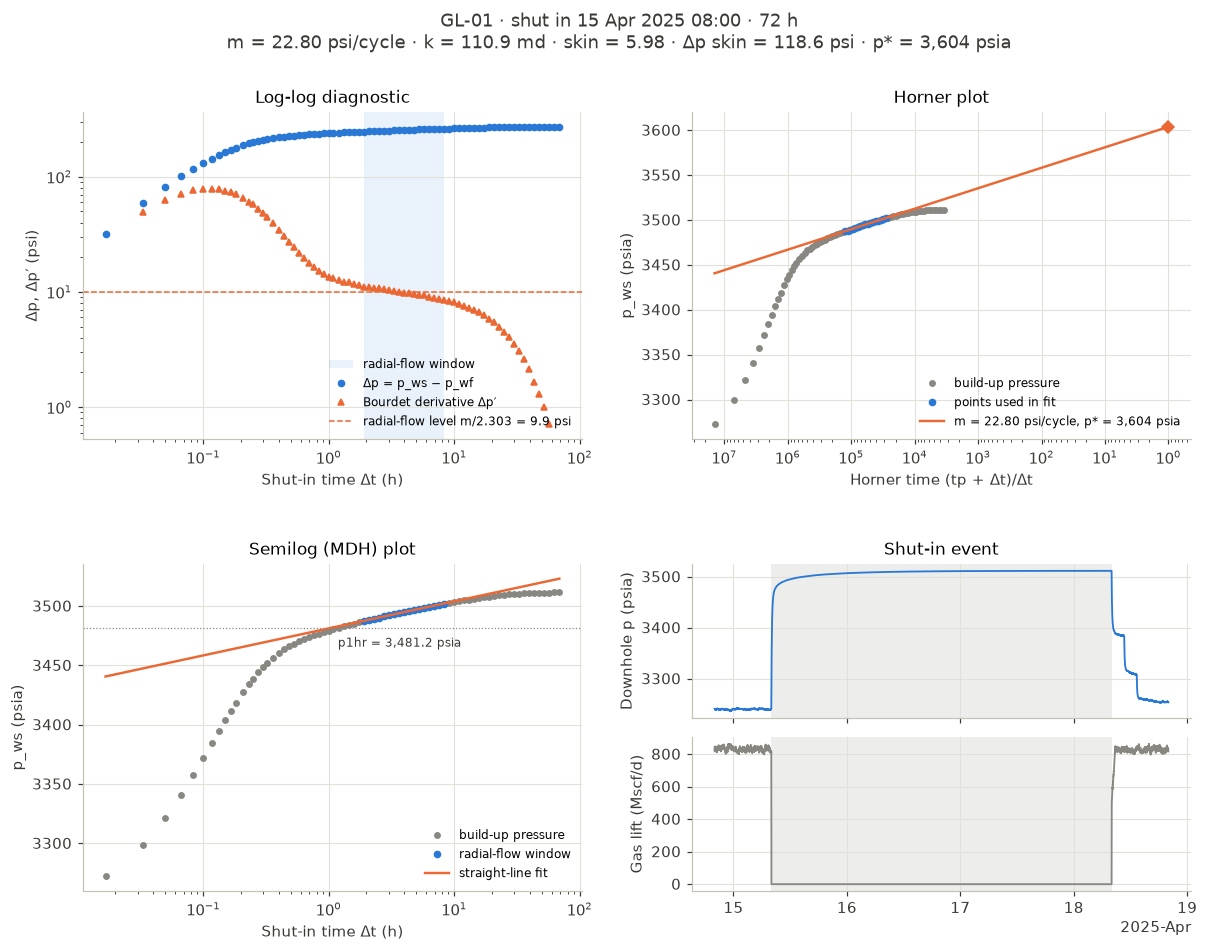

Damaged well. Skin 5.98 costs 119 psi of drawdown, so only 67% of the pressure drop does useful work (flow efficiency 0.67). Candidate for a stimulation review. Permeability 111 md over 80 ft of net pay (kh = 8,869 md·ft), using the VFM oil rate of 1,017 STB/d on 2025-04-14. By the end of the radial-flow window (8.3 h) the pressure signal has reached about 610 ft, still inside the 1,235 ft drainage radius, so the window is not distorted by boundaries. 



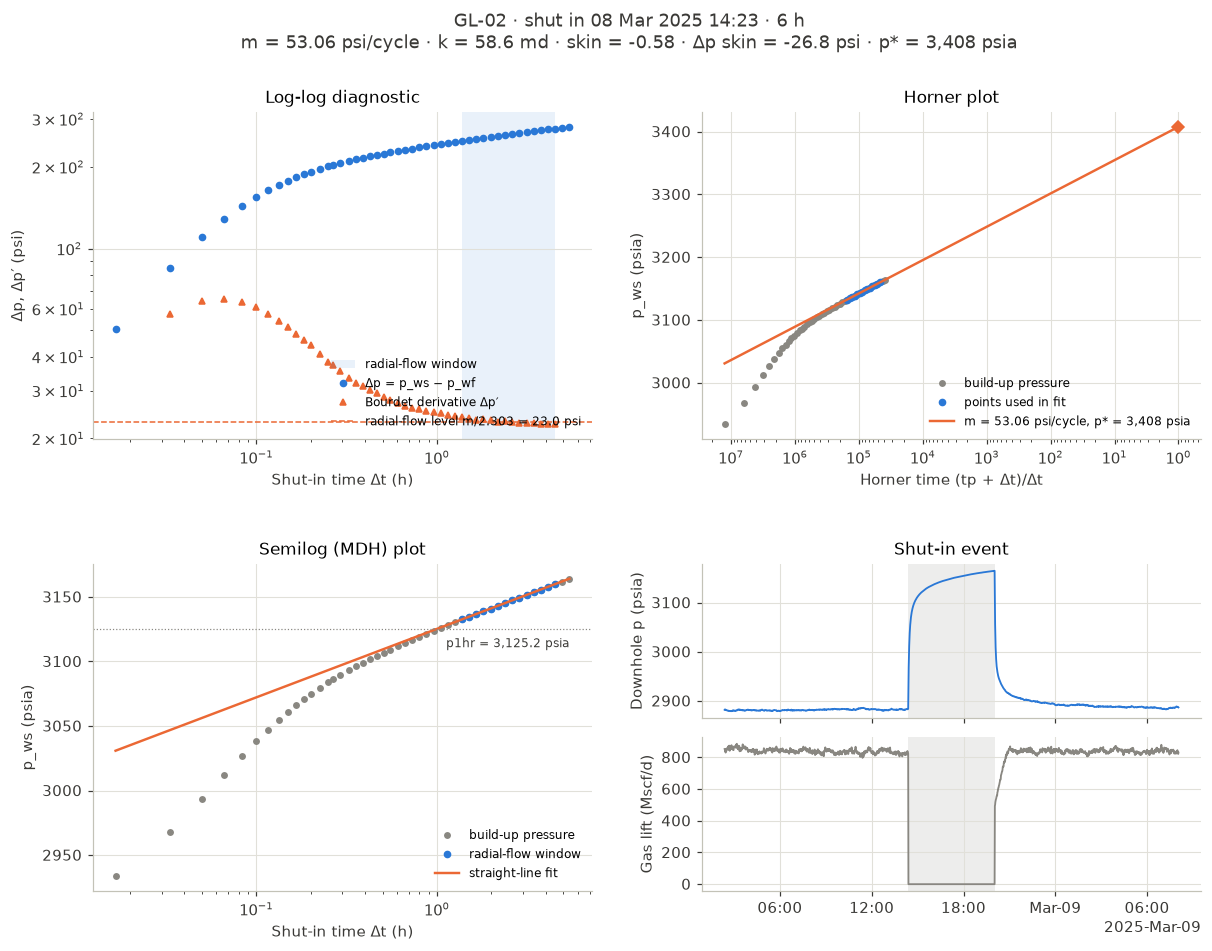

Undamaged or stimulated near-wellbore zone: skin -0.58 (Δpskin -27 psi, flow efficiency 1.05). Permeability 59 md over 82 ft of net pay (kh = 4,809 md·ft), using the VFM oil rate of 1,340 STB/d on 2025-03-07. By the end of the radial-flow window (4.5 h) the pressure signal has reached about 318 ft, still inside the 1,824 ft drainage radius, so the window is not distorted by boundaries. short shut-in (< 6 h) 



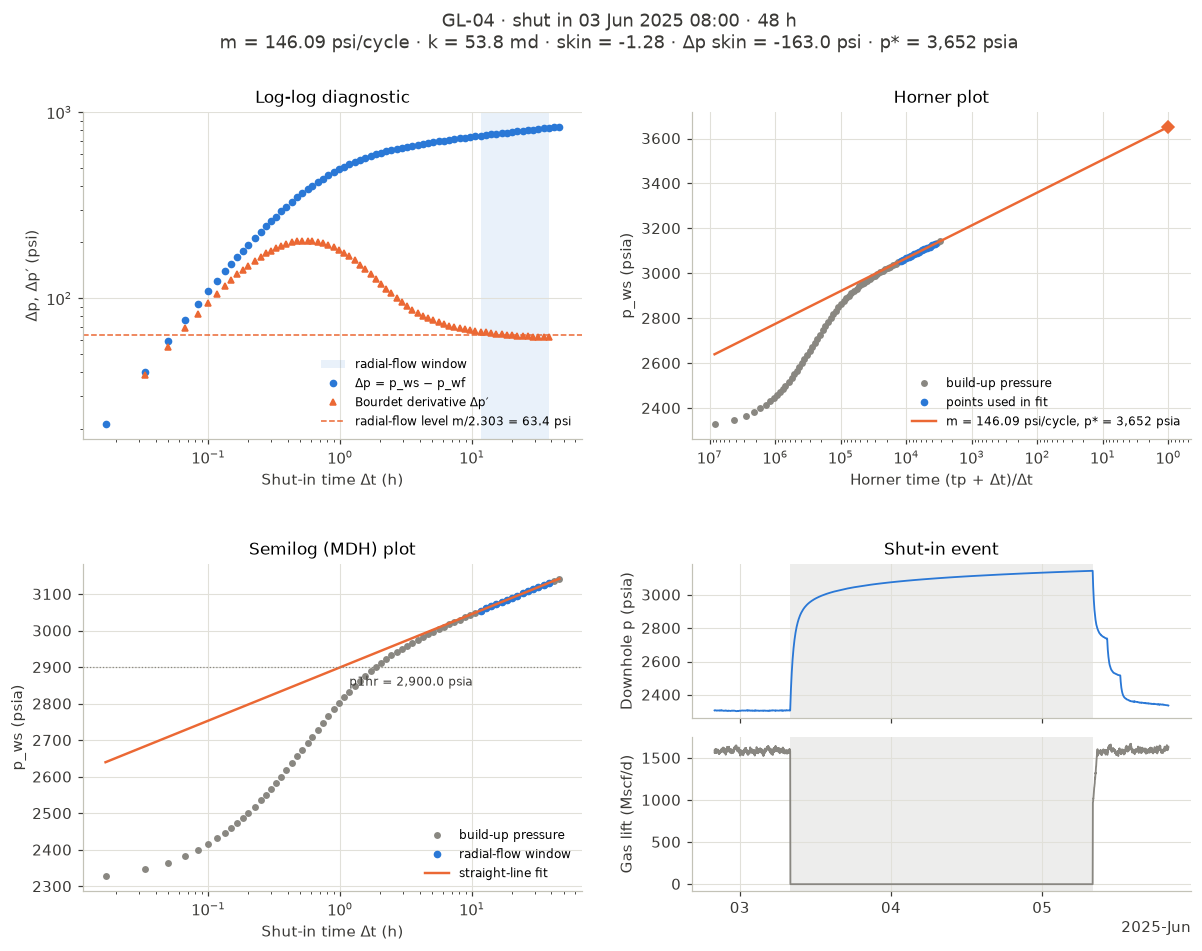

Undamaged or stimulated near-wellbore zone: skin -1.28 (Δpskin -163 psi, flow efficiency 1.12). Permeability 54 md over 32 ft of net pay (kh = 1,722 md·ft), using the VFM oil rate of 790 STB/d on 2025-06-02. By the end of the radial-flow window (38 h) the pressure signal has reached about 816 ft, still inside the 2,736 ft drainage radius, so the window is not distorted by boundaries. 



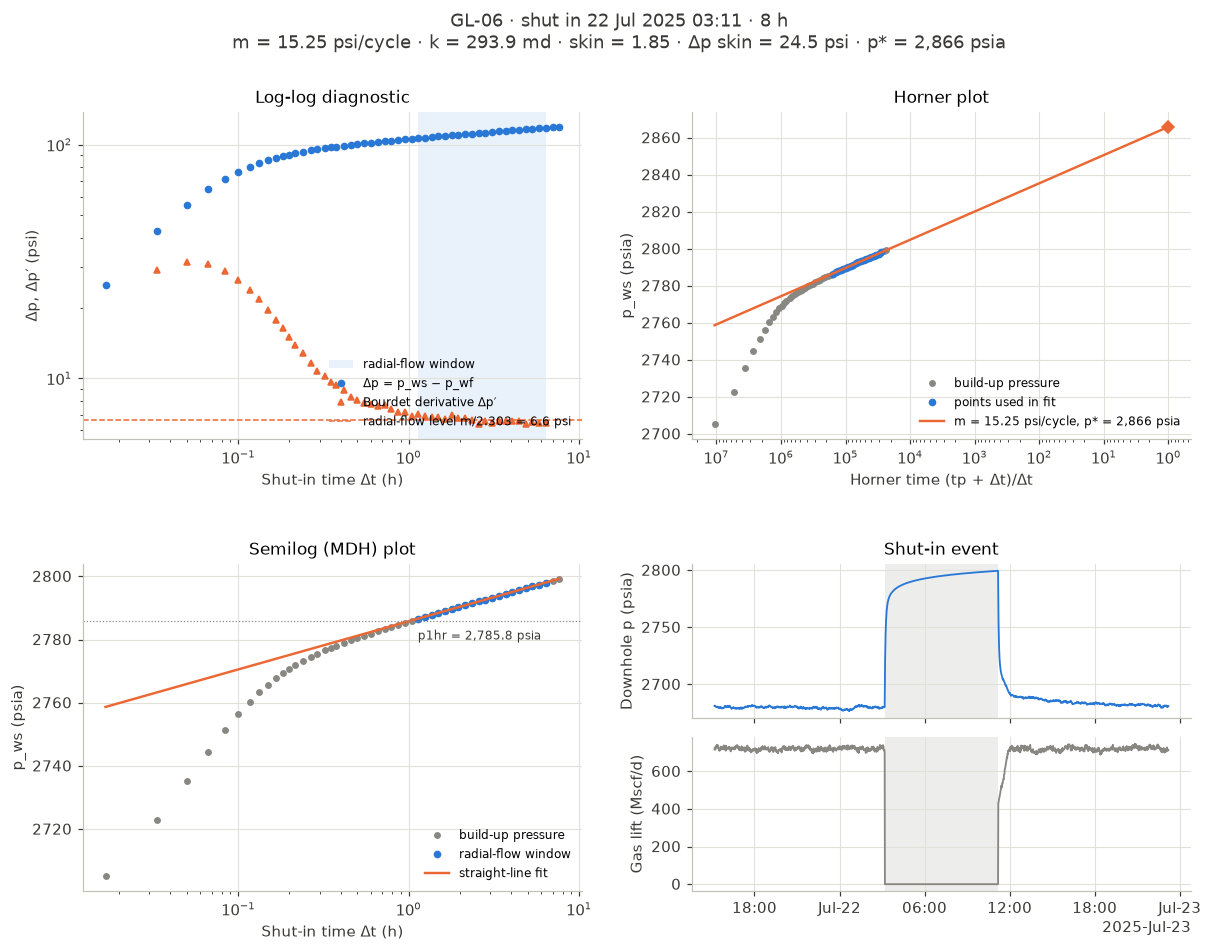

Mild near-wellbore damage: skin 1.85, Δpskin 25 psi, flow efficiency 0.87. Permeability 294 md over 68 ft of net pay (kh = 19,982 md·ft), using the VFM oil rate of 685 STB/d on 2025-07-21. By the end of the radial-flow window (6.4 h) the pressure signal has reached about 517 ft, still inside the 1,290 ft drainage radius, so the window is not distorted by boundaries. 



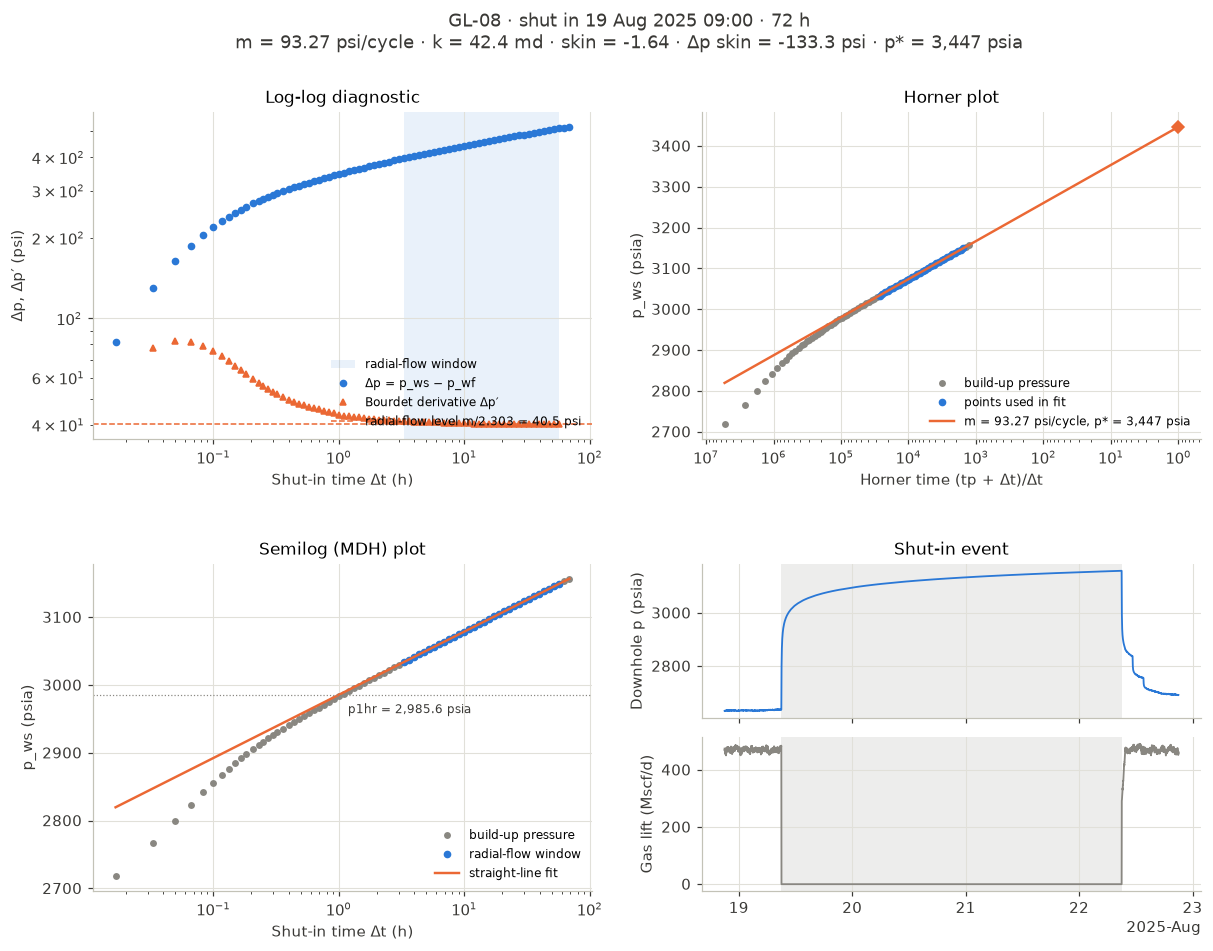

Undamaged or stimulated near-wellbore zone: skin -1.64 (Δpskin -133 psi, flow efficiency 1.16). Permeability 42 md over 65 ft of net pay (kh = 2,756 md·ft), using the VFM oil rate of 1,447 STB/d on 2025-08-18. By the end of the radial-flow window (57 h) the pressure signal has reached about 993 ft, still inside the 2,932 ft drainage radius, so the window is not distorted by boundaries. 



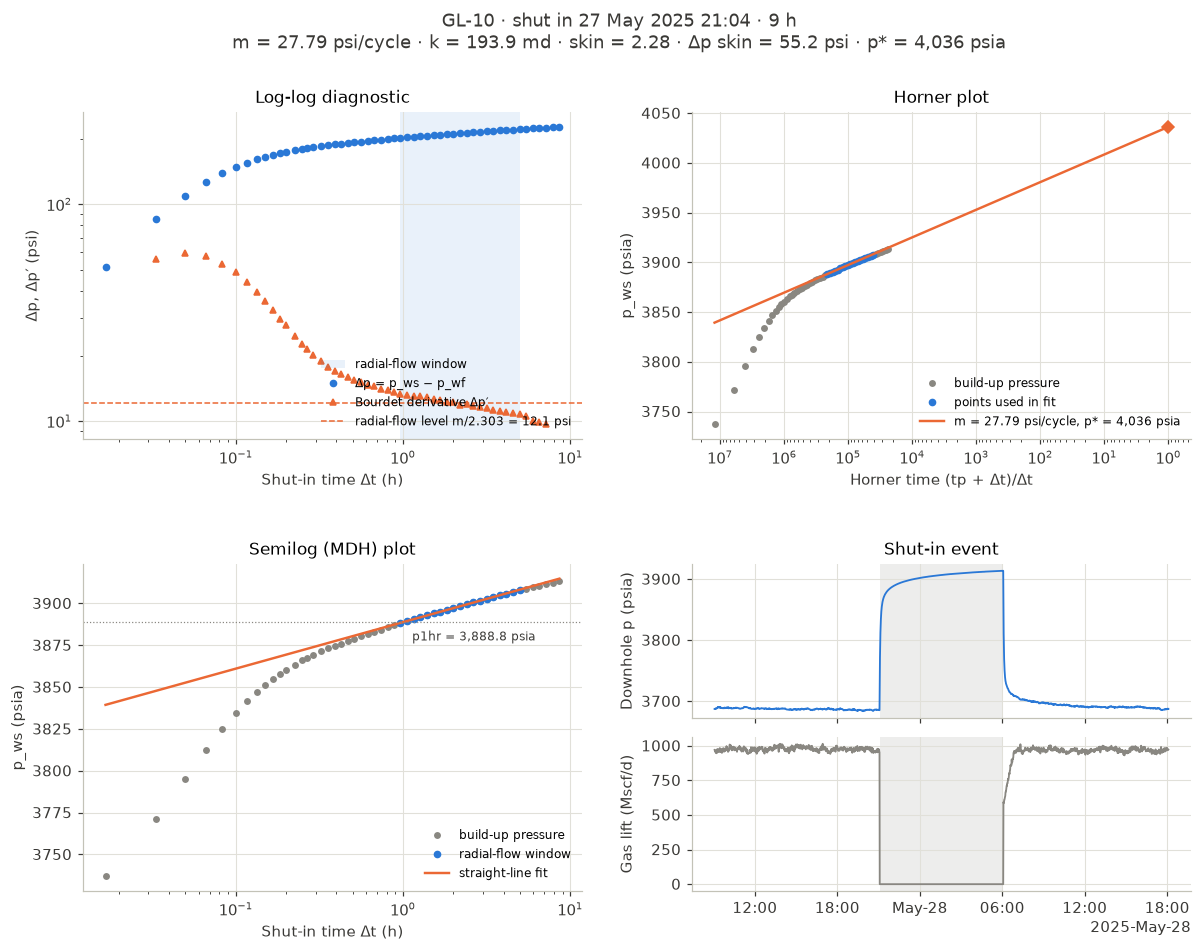

Mild near-wellbore damage: skin 2.28, Δpskin 55 psi, flow efficiency 0.84. Permeability 194 md over 136 ft of net pay (kh = 26,371 md·ft), using the VFM oil rate of 1,869 STB/d on 2025-05-26. By the end of the radial-flow window (5 h) the pressure signal has reached about 447 ft, still inside the 1,178 ft drainage radius, so the window is not distorted by boundaries. 



In [13]:
for key, r in ws.pta_objs.items():
    fig = SP.event_figure(ws.minute, r); plt.show()
    print(interpret_text(r, ws.static), "\n")

**Check against the reference PTA answers.** If the organisers' `pta_results.csv` is in `data/raw`, the build-ups
that fall inside the training period are compared with it here (it is never used for fitting; events outside the training
period cannot be compared because their pressure data is not in the training set).

In [14]:
ref_path = C.DATA_RAW / "pta_results.csv"
if ref_path.exists():
    ref = pd.read_csv(ref_path)
    print("reference columns:", list(ref.columns))
    tcol = next((c for c in ref.columns if "shut" in c.lower() or "date" in c.lower() or "time" in c.lower()), None)
    if tcol is not None:
        ref["_t"] = pd.to_datetime(ref[tcol], errors="coerce")
        ours = PL.pta_deliverable(ws.pta).assign(_t=lambda x: pd.to_datetime(x.t_shut))
        cmp = pd.merge_asof(ours.sort_values("_t"), ref.sort_values("_t"), on="_t", by="well_name",
                            tolerance=pd.Timedelta(days=2), suffixes=("", "_ref"))
        keep = [c for c in cmp.columns if c in ("well_name", "t_shut", "k_md", "skin", "m_psi_cycle", "dP_skin")
                or c.endswith("_ref") or any(k in c.lower() for k in ("perm", "skin", "slope", "dp_skin"))]
        display(cmp[keep])
    else:
        display(ref.head())
else:
    print("no reference file in data/raw: skipped")

reference columns: ['well_name', 't_shut', 'duration_hr', 'm_psi_cycle', 'k_md', 'skin', 'dP_skin']


,well_name,t_shut,m_psi_cycle,k_md,skin,dP_skin,t_shut_ref,duration_hr_ref,m_psi_cycle_ref,k_md_ref,skin_ref,dP_skin_ref
0,GL-02,2025-03-08 14:23:00,53.062,58.640,-0.581,-26.839,2025-03-08 14:23:00,5.65,53.692,55.811,-0.643,-30.023
1,GL-01,2025-04-15 08:00:00,22.803,110.864,5.977,118.579,2025-04-15 08:00:00,72.00,23.166,105.649,5.787,116.643
2,GL-10,2025-05-27 21:04:00,27.793,193.908,2.284,55.231,2025-05-27 21:04:00,9.00,28.471,177.974,2.141,53.022
3,GL-04,2025-06-03 08:00:00,146.094,53.821,-1.283,-163.032,2025-06-03 08:00:00,48.00,147.885,53.016,-1.354,-174.222
4,GL-06,2025-07-22 03:11:00,15.252,293.858,1.847,24.504,2025-07-22 03:11:00,8.00,15.159,292.163,1.891,24.945
5,GL-08,2025-08-19 09:00:00,93.273,42.394,-1.643,-133.295,2025-08-19 09:00:00,72.00,92.801,42.128,-1.613,-130.204


**Check of the PTA engine on synthetic build-ups with known answers** (analytical wellbore-storage + skin solution,
Stehfest inversion, 0.3 psi gauge noise). Permeability is recovered within a few percent and skin within about 0.2:

In [15]:
sys.path.insert(0, str(C.ROOT / "tests"))
from test_pta_synthetic import run_case, CASES     # same cases as the automated test
rows = []
for k_true, s_true, c_storage in CASES:
    r = run_case(k_true, s_true, c_storage)
    rows.append({"true k (md)": k_true, "recovered k": round(r.k_md, 1), "k error %": round(100 * (r.k_md / k_true - 1), 1),
                 "true skin": s_true, "recovered skin": round(r.skin, 2)})
pd.DataFrame(rows)

,true k (md),recovered k,k error %,true skin,recovered skin
0,110.0,109.1,-0.8,6.0,5.89
1,55.0,53.8,-2.2,-0.6,-0.74
2,290.0,287.5,-0.8,1.9,1.82
3,42.0,41.0,-2.3,-1.6,-1.73
4,25.0,24.6,-1.6,0.5,0.38


## 4. Export the submission files

In [16]:
paths = PL.export_all(ws)
for k, v in paths.items():
    print(f"{k:<11} {Path(v).relative_to(C.RESULTS.parent)}")

vfm_csv     results\vfm_daily_predictions.csv
vfm_xlsx    results\vfm_daily_predictions.xlsx
pta_csv     results\pta_results.csv
pta_xlsx    results\pta_results.xlsx
vfm_report  results\vfm_report.xlsx
pta_report  results\pta_report.xlsx
pta_plots   results\pta_plots
model       models\vfm_model.pkl


## 5. Using the saved model on new data

The application loads `models/vfm_model.pkl` and runs it on uploaded raw files without retraining. Here the last six
weeks of sensor data stand in for new data. **These well tests were part of the training set**, so the score below only
shows that the mechanics work; the honest accuracy estimate is the forward-chaining validation in section 2. With the
evaluation data, the same call scores the model on genuinely unseen tests, and `recalibrate=True` would then refit the
flow meter on the training tests plus the new ones (the app offers this as a checkbox).

In [17]:
bundle = PL.load_bundle()
base = PL.workspace_from_bundle(bundle)              # model + reference tables only, no sensor data
raw = PL.D.load_hf_raw()
new_hf = raw[raw.timestamp >= raw.timestamp.max() - pd.Timedelta(days=42)]
new_tests = PL.D.load_tests_raw(); new_tests = new_tests[new_tests.test_start >= new_hf.timestamp.min()]
new = PL.apply_to_new_hf(base, new_hf, tests_file=new_tests)
print(f"{len(new.vfm_daily):,} well-days predicted, {len(new.pta)} shut-ins interpreted")
V.score(new.test_eval).round(2)

430 well-days predicted, 1 shut-ins interpreted


,model,n_tests,oil MAE,oil MAPE %,oil bias %,water MAE,water MAPE %,water bias %,gas MAE,gas MAPE %,gas bias %
0,VFM,12,16.90,1.68,0.17,8.62,1.67,0.03,11.03,3.67,0.83
1,Last test carried forward,12,88.13,7.45,5.19,36.95,5.30,1.15,29.98,12.05,6.57
